# 🌾 Rice Leaf Disease Classification: EfficientNetV2-S vs. Vision Transformer (ViT-Base)

**Author:** Research Team | **Dataset:** 6 Classes Rice Disease Leaf Images

> **Research Purpose & Architecture Evolution:**
> In previous iterations with CNNs (EfficientNetV2-S and ConvNeXtBase), Explainable AI (Grad-CAM) revealed that deep convolutions can suffer from **shortcut learning / background noise bias** (e.g., attending to dense background weeds rather than focal leaf lesions).
> This revised benchmark evaluates **Vision Transformer (ViT-B/16)** against **EfficientNetV2-S**:
> - **Model A (CNN):** `EfficientNetV2-S` (Fast, lightweight ~20.7M parameters with fine-grained local lesion focus).
> - **Model B (Transformer):** `Vision Transformer (ViT-Base / vit-base-patch16-224)` (~86M parameters with Multi-Head Self-Attention capturing long-range global leaf context).
> - **Explainable AI (XAI):** High-resolution Grad-CAM / Attention Rollout comparison to verify whether ViT eliminates background artifact focus.

In [ ]:
# ==============================================================================
# 📌 CELL 1: Setup Environment & Mount Google Drive
# ==============================================================================
# คำอธิบาย:
# เชื่อมต่อ Google Drive สำหรับจัดเก็บ Dataset, โมเดล และรายงานผลลัพธ์
# ใช้ Keras 3 Native Architecture สำหรับ Vision Transformer (ไม่ต้องติดตั้ง Hugging Face แปลงข้ามเฟรมเวิร์ก ป้องกันบั๊ก Keras 3 compatibility)

from google.colab import drive
drive.mount('/content/drive')
print("✅ Google Drive mounted successfully!")
print("✅ Keras Native Environment Ready!")


Mounted at /content/drive
✅ Google Drive mounted successfully!


---
### 💡 Optional Helper: Unzip Dataset (Run only if you uploaded `dataset.zip`)
If you uploaded your dataset as a `.zip` archive to save upload time, uncomment and run the cell below.


In [ ]:
# OPTIONAL: Uncomment and run if you uploaded dataset.zip to your Google Drive root:
# !mkdir -p /content/drive/MyDrive/RiceDiseaseClassification/dataset
# !unzip -q /content/drive/MyDrive/RiceDiseaseClassification/dataset.zip -d /content/drive/MyDrive/RiceDiseaseClassification/dataset
# print("✅ Dataset unzipped successfully!")


---
## ⚠️ SECTION 0: PATH CONFIGURATION (CHECK AND EDIT IF NEEDED)
> **CRITICAL CHECK:** Ensure `BASE_DRIVE_DIR` matches the exact location where your dataset is stored in Google Drive. If your folder in Google Drive has a different name, change it here!


In [ ]:
# ==============================================================================
# 📌 CELL 5: Configure Folder Paths in Google Drive
# ==============================================================================
# คำอธิบาย:
# กำหนดโครงสร้างโฟลเดอร์สำหรับเก็บชุดข้อมูล (Dataset), โมเดล EfficientNetV2-S, โมเดล ViT-Base,
# และภาพการอธิบายผลการทำนาย (Grad-CAM & ViT Attention Maps)

import os

# Root folder in your Google Drive:
BASE_DRIVE_DIR = "/content/drive/MyDrive/RiceDiseaseClassification"

# Raw dataset folder containing the 6 disease subfolders:
DATASET_DIR = os.path.join(BASE_DRIVE_DIR, "dataset")

# Shared directory for split CSVs and class mapping:
SHARED_DIR = os.path.join(BASE_DRIVE_DIR, "shared")

# Output paths for Model A (EfficientNetV2-S):
EFFNET_DIR = os.path.join(BASE_DRIVE_DIR, "EfficientNetV2S")
EFFNET_MODEL_DIR = os.path.join(EFFNET_DIR, "models")
EFFNET_OUTPUT_DIR = os.path.join(EFFNET_DIR, "outputs")

# Output paths for Model B (Vision Transformer - ViT-Base):
VIT_DIR = os.path.join(BASE_DRIVE_DIR, "ViT_Base")
VIT_MODEL_DIR = os.path.join(VIT_DIR, "models")
VIT_OUTPUT_DIR = os.path.join(VIT_DIR, "outputs")

# Directory for Explainable AI visuals (Grad-CAM & Attention Maps):
GRADCAM_DIR = os.path.join(BASE_DRIVE_DIR, "gradcam_visuals")

# Create all output directories automatically:
for d in [SHARED_DIR, EFFNET_MODEL_DIR, EFFNET_OUTPUT_DIR, VIT_MODEL_DIR, VIT_OUTPUT_DIR, GRADCAM_DIR]:
    os.makedirs(d, exist_ok=True)

print("📁 Configured paths:")
print(f"  - Dataset Directory: {DATASET_DIR}")
print(f"  - Shared Directory:  {SHARED_DIR}")
print(f"  - EffNet Directory:  {EFFNET_DIR}")
print(f"  - ViT Directory:     {VIT_DIR}")

if os.path.exists(DATASET_DIR):
    print(f"\n✅ SUCCESS: Found dataset folder at: {DATASET_DIR}")
else:
    print(f"\n❌ WARNING: Dataset folder NOT found at: {DATASET_DIR}")
    print("   Please verify your Google Drive folder name and update BASE_DRIVE_DIR above.")


📁 Configured paths:
  - Dataset Directory: /content/drive/MyDrive/RiceDiseaseClassification/dataset
  - Shared Directory:  /content/drive/MyDrive/RiceDiseaseClassification/shared
  - EffNet Directory:  /content/drive/MyDrive/RiceDiseaseClassification/EfficientNetV2S
  - ConvNeXt Dir:      /content/drive/MyDrive/RiceDiseaseClassification/ConvNeXtBase

✅ SUCCESS: Found dataset folder at: /content/drive/MyDrive/RiceDiseaseClassification/dataset


---
## 1. Environment Verification & Hardware Setup
We verify GPU acceleration, print CUDA specifications, import standard scientific libraries, and lock random seeds across Python, NumPy, and TensorFlow to ensure reproducible data splitting and initializations.


In [ ]:
import sys
import time
import json
import random
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

print(f"Python Version:     {platform.python_version()}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {tf.keras.__version__}")

# Verify GPU device availability
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✅ GPU Accelerator Detected: {gpus[0].name}")
    !nvidia-smi --query-gpu=name,memory.total,memory.free --format=csv
else:
    print("⚠️ No GPU detected! Running on CPU. Navigate to Runtime -> Change runtime type -> T4 GPU.")

# Enforce deterministic random seed
RANDOM_SEED = 42
def set_seed(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(RANDOM_SEED)
print(f"🔒 Global random seed set to {RANDOM_SEED} across Python, NumPy, and TensorFlow.")


Python Version:     3.13.16
TensorFlow Version: 2.21.0
Keras Version:      3.13.2
✅ GPU Accelerator Detected: /physical_device:GPU:0
name, memory.total [MiB], memory.free [MiB]
Tesla T4, 15360 MiB, 14910 MiB
🔒 Global random seed set to 42 across Python, NumPy, and TensorFlow.


---
## 2. Dataset Scanning, Validation & Stratified Splitting
We inspect all images in the raw dataset, verify that files are readable, identify corrupt items, and generate a **75% Train / 10% Validation / 15% Test** stratified split with a fixed random seed (`seed=42`).

> **Fairness Guarantee:** Both models will be trained on the exact same training partition and evaluated on the exact same unseen test partition.


In [ ]:
# Canonical 6 classes in strict consistent order
EXPECTED_CLASSES = [
    "Bacterial Leaf Blight",
    "Brown Spot",
    "Healthy Rice Leaf",
    "Leaf Blast",
    "Leaf Scald",
    "Sheath Blight"
]

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def scan_dataset(dataset_dir):
    """Scans dataset directory, validates image integrity, and records image metadata."""
    records = []
    class_dirs = {}

    subdirs = [d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))]
    subdir_map = {d.strip().lower(): d for d in subdirs}

    for c in EXPECTED_CLASSES:
        c_lower = c.lower()
        if c_lower in subdir_map:
            class_dirs[c] = os.path.join(dataset_dir, subdir_map[c_lower])
        else:
            # Partial / whitespace-insensitive match
            matched = None
            for key, val in subdir_map.items():
                if key.replace(" ", "") == c_lower.replace(" ", ""):
                    matched = os.path.join(dataset_dir, val)
                    break
            if matched:
                class_dirs[c] = matched
            else:
                raise ValueError(f"Missing required class folder: '{c}' in {dataset_dir}")

    print("=" * 65)
    print("VALIDATING IMAGES ACROSS ALL 6 TARGET CLASSES")
    print("=" * 65)

    for class_name in EXPECTED_CLASSES:
        folder = class_dirs[class_name]
        files = [f for f in os.listdir(folder) if Path(f).suffix.lower() in VALID_EXTENSIONS]
        corrupted = 0
        valid_files = 0

        for fname in files:
            fpath = os.path.join(folder, fname)
            try:
                with Image.open(fpath) as img:
                    img.verify()
                with Image.open(fpath) as img:
                    w, h = img.size
                records.append({
                    "image_path": fpath,
                    "class_name": class_name,
                    "width": w,
                    "height": h,
                    "is_valid": True
                })
                valid_files += 1
            except Exception as e:
                corrupted += 1
                records.append({
                    "image_path": fpath,
                    "class_name": class_name,
                    "width": None,
                    "height": None,
                    "is_valid": False
                })
        print(f"  - {class_name:24s}: {valid_files:4d} valid images (corrupt: {corrupted})")

    df = pd.DataFrame(records)
    valid_df = df[df["is_valid"]].copy()
    print("=" * 65)
    print(f"Total valid images: {len(valid_df):,}")
    return valid_df

# Run scanner
valid_records_df = scan_dataset(DATASET_DIR)


VALIDATING IMAGES ACROSS ALL 6 TARGET CLASSES
  - Bacterial Leaf Blight   :  636 valid images (corrupt: 0)
  - Brown Spot              :  646 valid images (corrupt: 0)
  - Healthy Rice Leaf       :  653 valid images (corrupt: 0)
  - Leaf Blast              :  634 valid images (corrupt: 0)
  - Leaf Scald              :  628 valid images (corrupt: 0)
  - Sheath Blight           :  632 valid images (corrupt: 0)
Total valid images: 3,829


In [ ]:
def create_or_load_stratified_split(df_valid, shared_dir, dataset_dir, seed=42):
    """
    Performs 75% Train, 10% Val, 15% Test stratified split.
    If clean manifests or standard split CSVs already exist in shared_dir, loads them
    and dynamically rebinds image paths to the Colab Google Drive dataset folder!
    """
    train_csv = os.path.join(shared_dir, "train.csv")
    val_csv = os.path.join(shared_dir, "validation.csv")
    test_csv = os.path.join(shared_dir, "test.csv")
    class_names_json = os.path.join(shared_dir, "class_names.json")

    # Save canonical class mapping
    with open(class_names_json, "w", encoding="utf-8") as f:
        json.dump(EXPECTED_CLASSES, f, indent=2)

    # Check for either clean manifests (clean_train.csv) or standard (train.csv)
    if os.path.exists(os.path.join(shared_dir, "clean_train.csv")) and not os.path.exists(train_csv):
        print("🔍 Detected clean manifests ('clean_train.csv', etc.) in shared_dir!")
        train_csv = os.path.join(shared_dir, "clean_train.csv")
        val_csv = os.path.join(shared_dir, "clean_validation.csv")
        test_csv = os.path.join(shared_dir, "clean_test.csv")

    if os.path.exists(train_csv) and os.path.exists(val_csv) and os.path.exists(test_csv):
        print(f"✅ Loading existing split manifests: {os.path.basename(train_csv)}, etc.")
        train_df = pd.read_csv(train_csv)
        val_df = pd.read_csv(val_csv)
        test_df = pd.read_csv(test_csv)
    else:
        print("⚡ No existing split manifests found in shared_dir. Generating new stratified 75/10/15 split...")
        class_to_idx = {name: idx for idx, name in enumerate(EXPECTED_CLASSES)}
        df_valid["numeric_class_index"] = df_valid["class_name"].map(class_to_idx)

        # Split off 15% test
        train_val_df, test_df = train_test_split(
            df_valid,
            test_size=0.15,
            random_state=seed,
            stratify=df_valid["class_name"]
        )
        # Split remaining 85% into 75% train and 10% val
        val_ratio = 0.10 / (0.75 + 0.10)
        train_df, val_df = train_test_split(
            train_val_df,
            test_size=val_ratio,
            random_state=seed,
            stratify=train_val_df["class_name"]
        )

        cols = ["image_path", "class_name", "numeric_class_index"]
        train_df = train_df[cols].copy()
        val_df = val_df[cols].copy()
        test_df = test_df[cols].copy()

        train_df.to_csv(os.path.join(shared_dir, "train.csv"), index=False)
        val_df.to_csv(os.path.join(shared_dir, "validation.csv"), index=False)
        test_df.to_csv(os.path.join(shared_dir, "test.csv"), index=False)
        print("✅ New manifests saved to Google Drive shared directory.")

    # Reset indices to guarantee clean 0..N-1 indexing
    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    # 🔄 Dynamically rebind image_path to the active Colab dataset directory:
    def rebind_path(row):
        fname = os.path.basename(str(row["image_path"]).replace("\\", "/"))
        return os.path.join(dataset_dir, str(row["class_name"]), fname)

    train_df["image_path"] = train_df.apply(rebind_path, axis=1)
    val_df["image_path"] = val_df.apply(rebind_path, axis=1)
    test_df["image_path"] = test_df.apply(rebind_path, axis=1)

    # Verify that files exist on Google Drive
    missing_test = sum(not os.path.exists(p) for p in test_df["image_path"])
    if missing_test == 0:
        print(f"✅ Verified: 100% of test image paths exist in Google Drive ({len(test_df)} images).")
    else:
        print(f"⚠️ Warning: {missing_test} images in test set could not be found at {dataset_dir}!")

    print(f"  - Train Set:      {len(train_df):4d} images ({len(train_df)/(len(train_df)+len(val_df)+len(test_df))*100:.1f}%)")
    print(f"  - Validation Set: {len(val_df):4d} images ({len(val_df)/(len(train_df)+len(val_df)+len(test_df))*100:.1f}%)")
    print(f"  - Test Set:       {len(test_df):4d} images ({len(test_df)/(len(train_df)+len(val_df)+len(test_df))*100:.1f}%)")

    return train_df, val_df, test_df

train_df, val_df, test_df = create_or_load_stratified_split(valid_records_df, SHARED_DIR, DATASET_DIR, seed=RANDOM_SEED)

✅ Loading existing split manifests: train.csv, etc.
✅ Verified: 100% of test image paths exist in Google Drive (570 images).
  - Train Set:      2847 images (75.0%)
  - Validation Set:  381 images (10.0%)
  - Test Set:        570 images (15.0%)


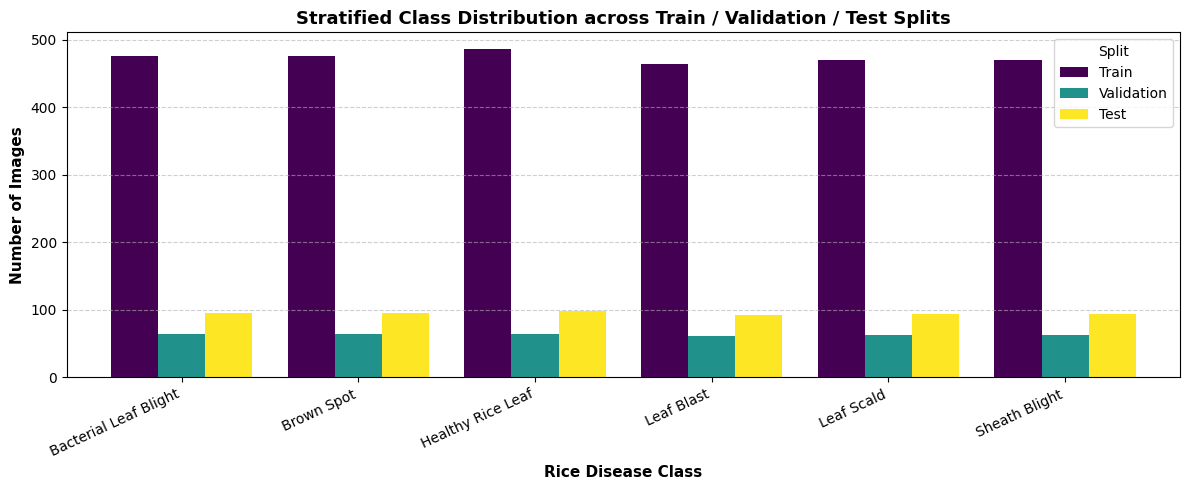

                       Train  Validation  Test
class_name                                    
Bacterial Leaf Blight    477          64    95
Brown Spot               477          64    96
Healthy Rice Leaf        487          65    98
Leaf Blast               464          62    93
Leaf Scald               471          63    94
Sheath Blight            471          63    94


In [ ]:
# Visualize class distributions across splits
dist_df = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Validation": val_df["class_name"].value_counts(),
    "Test": test_df["class_name"].value_counts()
}).loc[EXPECTED_CLASSES]

ax = dist_df.plot(kind="bar", figsize=(12, 5), width=0.8, colormap="viridis")
plt.title("Stratified Class Distribution across Train / Validation / Test Splits", fontsize=13, fontweight="bold")
plt.xlabel("Rice Disease Class", fontsize=11, fontweight="bold")
plt.ylabel("Number of Images", fontsize=11, fontweight="bold")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend(title="Split")
plt.tight_layout()
plt.savefig(os.path.join(SHARED_DIR, "split_distribution.png"), dpi=200)
plt.show()
print(dist_df)


---
## 3. Data Augmentation & High-Performance Data Pipeline
We construct an asynchronous `tf.data.Dataset` pipeline using `tf.data.AUTOTUNE`, prefetching, and architecture-appropriate preprocessing:
- **Augmentation (Train only):** Random Horizontal Flip, Random Rotation (±10%), Random Zoom (±10%), Random Translation (±8%).
- **Validation & Test data:** Completely unaugmented to preserve evaluation integrity.
- **Model-Specific Preprocessing:**
  - EfficientNetV2-S: `tf.keras.applications.efficientnet_v2.preprocess_input`
  - ConvNeXtBase: `tf.keras.applications.convnext.preprocess_input`


In [ ]:
# ==============================================================================
# 📌 CELL 13: Robust Data Augmentation Pipeline (Level 2: Background Noise Suppression)
# ==============================================================================
# คำอธิบาย:
# ออกแบบ Data Augmentation พิเศษเพื่อแก้ปัญหา Shortcut Learning / Background Noise:
# 1. RandomCrop & RandomZoom เพื่อบีบให้โมเดลโฟกัสที่ใบข้าวตรงกลาง ลดการจำพุ่มไม้ฉากหลัง
# 2. RandomFlip & Translation เพื่อสร้างความคงทนของรอยโรคในทุกมุมมอง
# 3. Contrast & Brightness Jitter เพื่อจำลองแสงแดดในแปลงนาจริง

data_augmentation_layer = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.12),
    # Zoom-in เพื่อขยายบริเวณแผลบนใบและลดสัดส่วนของพื้นหลัง
    layers.RandomZoom(height_factor=(-0.15, 0.15), width_factor=(-0.15, 0.15)),
    layers.RandomTranslation(height_factor=0.08, width_factor=0.08),
    layers.RandomContrast(0.15)
], name="leaf_focused_augmentation")

def build_dataset_from_df(
    df,
    preprocess_fn,
    img_size=(224, 224),
    batch_size=32,
    is_training=False,
    augmenter=None,
    shuffle_buffer=1024
):
    """
    Creates an optimized tf.data.Dataset pipeline with parallel disk prefetching.
    """
    paths = df["image_path"].values
    labels = df["class_index"].values.astype(np.int64)

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if is_training:
        dataset = dataset.shuffle(buffer_size=min(len(df), shuffle_buffer), seed=42)

    def _parse_img(path, label):
        raw = tf.io.read_file(path)
        img = tf.image.decode_jpeg(raw, channels=3)
        img = tf.image.resize(img, img_size)
        img = tf.cast(img, tf.float32)
        if preprocess_fn is not None:
            img = preprocess_fn(img)
        return img, label

    dataset = dataset.map(_parse_img, num_parallel_calls=tf.data.AUTOTUNE)

    if is_training and augmenter is not None:
        dataset = dataset.map(lambda x, y: (augmenter(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

print("✅ Enhanced augmentation and tf.data pipeline defined successfully.")


---
## 4. Model A: EfficientNetV2-S (Lightweight & Efficient)
- **Backbone:** `tf.keras.applications.EfficientNetV2S` (ImageNet pretrained, frozen feature extractor)
- **Head:** `GlobalAveragePooling2D` -> `Dense(256, relu)` -> `Dropout(0.3)` -> `Dense(6, softmax)`
- **Optimizer:** `Adam(learning_rate=0.0001)`
- **Regularization & Callbacks:**
  - `EarlyStopping` (patience=5, restore_best_weights=True)
  - `ReduceLROnPlateau` (factor=0.5, patience=2, min_lr=1e-6)
  - `ModelCheckpoint` (monitoring `val_loss`, saving best weights)


In [ ]:
from tensorflow.keras.applications.efficientnet_v2 import (
    EfficientNetV2S,
    preprocess_input as effnet_preprocess
)

def build_efficientnet_model(num_classes=6, input_shape=(224, 224, 3)):
    # include_preprocessing=False allows us to use our explicit tf.data preprocess_fn
    base_model = EfficientNetV2S(
        weights="imagenet",
        include_top=False,
        include_preprocessing=True,
        input_shape=input_shape
    )
    base_model.trainable = False  # Freeze pretrained feature extractor

    inputs = layers.Input(shape=input_shape, name="input_image")
    features = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(features)
    x = layers.Dense(256, activation="relu", name="fc_dense")(x)
    x = layers.Dropout(0.3, name="head_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="classification_head")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="RiceLeaf_EfficientNetV2S")
    return model, base_model

effnet_model, effnet_base = build_efficientnet_model()
effnet_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

total_p = int(effnet_model.count_params())
trainable_p = int(sum([tf.size(w).numpy() for w in effnet_model.trainable_weights]))
non_trainable_p = total_p - trainable_p

print("=" * 65)
print("EFFICIENTNETV2-S MODEL SUMMARY")
print(f"Total Parameters:         {total_p:,}")
print(f"Trainable Parameters:     {trainable_p:,}")
print(f"Non-Trainable Parameters: {non_trainable_p:,}")
print("=" * 65)


EFFICIENTNETV2-S MODEL SUMMARY
Total Parameters:         20,660,838
Trainable Parameters:     329,478
Non-Trainable Parameters: 20,331,360


In [ ]:
# Build tf.data datasets for EfficientNetV2-S
BATCH_SIZE = 32
IMG_SIZE = (224, 224)

effnet_train_ds = build_dataset_from_df(
    train_df, effnet_preprocess, img_size=IMG_SIZE, batch_size=BATCH_SIZE,
    is_training=True, augmenter=data_augmentation_layer
)
effnet_val_ds = build_dataset_from_df(
    val_df, effnet_preprocess, img_size=IMG_SIZE, batch_size=BATCH_SIZE,
    is_training=False
)

# Training Callbacks
effnet_ckpt_path = os.path.join(EFFNET_MODEL_DIR, "efficientnetv2s.keras")
effnet_callbacks = [
    callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    callbacks.ModelCheckpoint(filepath=effnet_ckpt_path, monitor="val_loss", save_best_only=True, verbose=1)
]

print("🚀 Starting EfficientNetV2-S Training on T4 GPU...")
t0_eff = time.time()
effnet_history = effnet_model.fit(
    effnet_train_ds,
    validation_data=effnet_val_ds,
    epochs=25,
    callbacks=effnet_callbacks,
    verbose=1
)
effnet_train_time = time.time() - t0_eff
print(f"✅ Training completed in {effnet_train_time:.2f} seconds ({effnet_train_time/60:.2f} mins).")

# Save training history to CSV
eff_hist_df = pd.DataFrame(effnet_history.history)
eff_hist_df.insert(0, "epoch", range(1, len(eff_hist_df) + 1))
eff_hist_df.to_csv(os.path.join(EFFNET_OUTPUT_DIR, "training_history.csv"), index=False)


🚀 Starting EfficientNetV2-S Training on T4 GPU...
Epoch 1/25
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 961ms/step - accuracy: 0.4395 - loss: 1.4142
Epoch 1: val_loss improved from None to 0.93165, saving model to /content/drive/MyDrive/RiceDiseaseClassification/EfficientNetV2S/models/efficientnetv2s.keras

Epoch 1: finished saving model to /content/drive/MyDrive/RiceDiseaseClassification/EfficientNetV2S/models/efficientnetv2s.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 159s 1s/step - accuracy: 0.5546 - loss: 1.1751 - val_accuracy: 0.6352 - val_loss: 0.9317 - learning_rate: 5.0000e-04
Epoch 2/25
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 691ms/step - accuracy: 0.6831 - loss: 0.8636
Epoch 2: val_loss improved from 0.93165 to 0.69561, saving model to /content/drive/MyDrive/RiceDiseaseClassification/EfficientNetV2S/models/efficientnetv2s.keras

Epoch 2: finished saving model to /content/drive/MyDrive/RiceDiseaseClassification/EfficientNetV2S/models/efficientnetv2s.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 66s 745ms/step - accuracy: 0

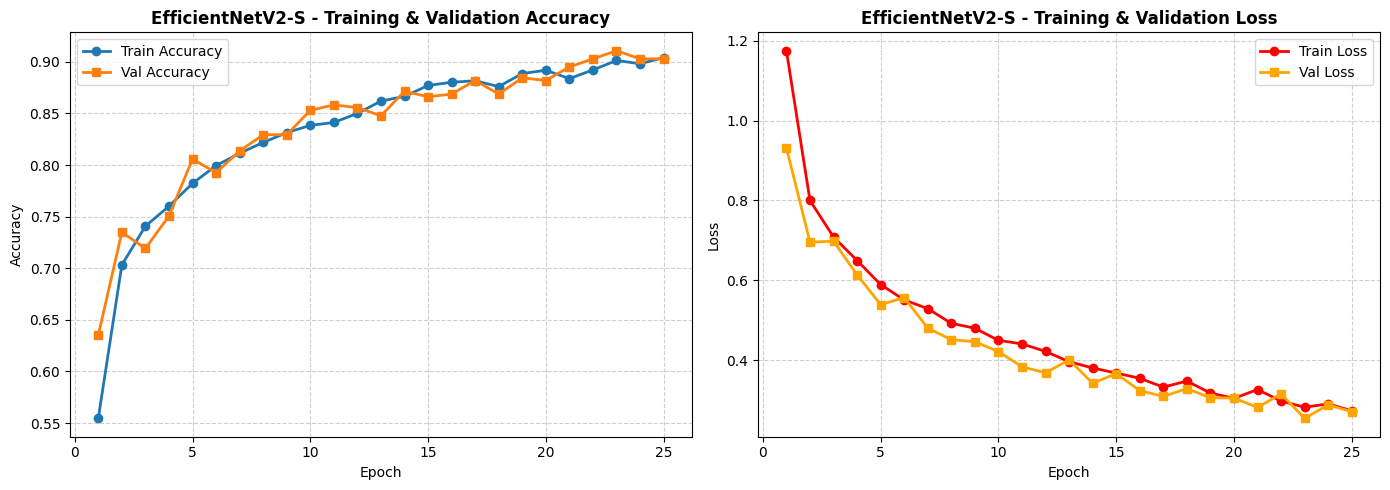

In [ ]:
# Plot EfficientNetV2-S Learning Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Curve
ax1.plot(eff_hist_df["epoch"], eff_hist_df["accuracy"], label="Train Accuracy", lw=2, marker='o')
ax1.plot(eff_hist_df["epoch"], eff_hist_df["val_accuracy"], label="Val Accuracy", lw=2, marker='s')
ax1.set_title("EfficientNetV2-S - Training & Validation Accuracy", fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

# Loss Curve
ax2.plot(eff_hist_df["epoch"], eff_hist_df["loss"], label="Train Loss", color="red", lw=2, marker='o')
ax2.plot(eff_hist_df["epoch"], eff_hist_df["val_loss"], label="Val Loss", color="orange", lw=2, marker='s')
ax2.set_title("EfficientNetV2-S - Training & Validation Loss", fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(EFFNET_OUTPUT_DIR, "efficientnetv2s_learning_curves.png"), dpi=200)
plt.show()


---
## 5. Model A: Test Set Evaluation & Latency Profiling
We evaluate EfficientNetV2-S exclusively on the unseen test set, calculating:
- Accuracy, Macro Precision, Macro Recall, Macro F1-Score
- Multiclass ROC-AUC (One-vs-Rest)
- Confusion Matrix Heatmap
- Inference Latency and FPS throughput on GPU


📊 Evaluating EfficientNetV2S on 570 Unseen Test Samples...
18/18 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step


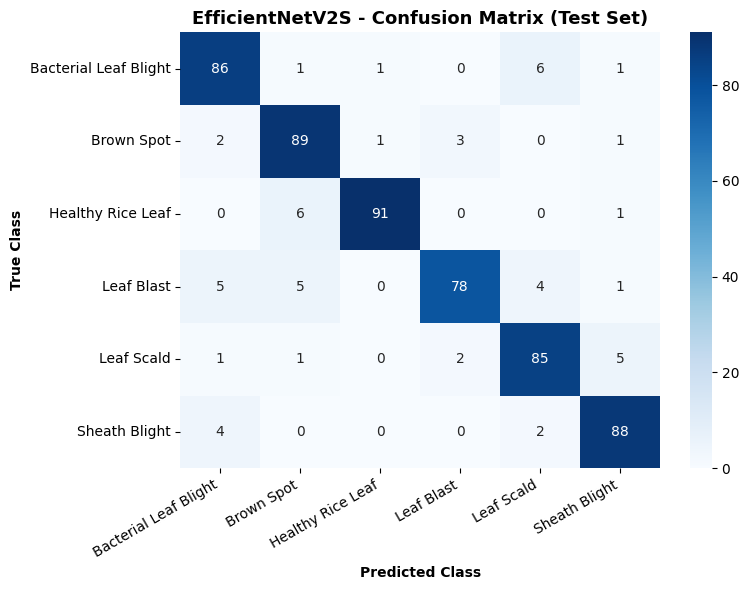

⏱️ Profiling inference latency on GPU...
RESULTS FOR EFFICIENTNETV2S
{
  "model_name": "EfficientNetV2S",
  "test_samples": 570,
  "accuracy": 0.907,
  "precision_macro": 0.9086,
  "recall_macro": 0.9067,
  "f1_score_macro": 0.9068,
  "roc_auc_macro": 0.991
}
Avg Latency: 640.45 ms | Throughput: 1.6 FPS


In [ ]:
def evaluate_model_pipeline(model, test_df, preprocess_fn, model_name, output_dir, img_size=(224, 224)):
    """
    Performs complete evaluation: predictions, metrics, confusion matrix, and standardized latency profiling.
    Uses @tf.function(reduce_retracing=True) to ensure fair, identical, GPU-accelerated profiling across all models!
    """
    print(f"📊 Evaluating {model_name} on {len(test_df)} Unseen Test Samples...")

    # Load all test images
    images = []
    for p in test_df["image_path"]:
        with Image.open(p) as img:
            rgb = img.convert("RGB").resize(img_size)
            arr = np.array(rgb, dtype=np.float32)
            images.append(preprocess_fn(arr))
    images = np.array(images, dtype=np.float32)
    y_true = test_df["numeric_class_index"].values

    # 1. Batch Prediction
    y_probs = model.predict(images, batch_size=32, verbose=1)
    y_pred = np.argmax(y_probs, axis=1)
    confidences = np.max(y_probs, axis=1)

    # 2. Compute Metrics
    acc = float(accuracy_score(y_true, y_pred))
    p_macro = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
    r_macro = float(recall_score(y_true, y_pred, average="macro", zero_division=0))
    f1_m = float(f1_score(y_true, y_pred, average="macro", zero_division=0))

    try:
        y_true_oh = tf.keras.utils.to_categorical(y_true, num_classes=len(EXPECTED_CLASSES))
        roc_macro = float(roc_auc_score(y_true_oh, y_probs, multi_class="ovr", average="macro"))
    except Exception as e:
        print(f"Warning: ROC-AUC calculation issue: {e}")
        roc_macro = None

    metrics = {
        "model_name": model_name,
        "test_samples": len(y_true),
        "accuracy": round(acc, 4),
        "precision_macro": round(p_macro, 4),
        "recall_macro": round(r_macro, 4),
        "f1_score_macro": round(f1_m, 4),
        "roc_auc_macro": round(roc_macro, 4) if roc_macro is not None else "N/A"
    }

    # Save Metrics JSON
    with open(os.path.join(output_dir, "metrics.json"), "w") as f:
        json.dump(metrics, f, indent=2)

    # 3. Classification Report
    clf_dict = classification_report(y_true, y_pred, target_names=EXPECTED_CLASSES, output_dict=True, zero_division=0)
    pd.DataFrame(clf_dict).transpose().to_csv(os.path.join(output_dir, "classification_report.csv"))

    # 4. Confusion Matrix Heatmap
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(EXPECTED_CLASSES))))
    cm_df = pd.DataFrame(cm, index=EXPECTED_CLASSES, columns=EXPECTED_CLASSES)
    cm_df.to_csv(os.path.join(output_dir, "confusion_matrix.csv"))

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=True,
                xticklabels=EXPECTED_CLASSES, yticklabels=EXPECTED_CLASSES)
    plt.title(f"{model_name} - Confusion Matrix (Test Set)", fontsize=13, fontweight="bold")
    plt.xlabel("Predicted Class", fontweight="bold")
    plt.ylabel("True Class", fontweight="bold")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f"{model_name.lower()}_confusion_matrix.png"), dpi=200)
    plt.show()

    # 5. Standardized Latency Profiling with @tf.function (Identical Benchmark across all models)
    print("⏱️ Profiling inference latency with compiled @tf.function...")

    @tf.function(reduce_retracing=True)
    def predict_step(inputs):
        return model(inputs, training=False)

    # Warmup
    warmup_tensor = tf.convert_to_tensor(images[:1], dtype=tf.float32)
    for _ in range(5):
        _ = predict_step(warmup_tensor)

    latencies = []
    for i in range(min(50, len(images))):
        single_img = tf.convert_to_tensor(images[i:i+1], dtype=tf.float32)
        t0 = time.perf_counter()
        _ = predict_step(single_img)
        latencies.append((time.perf_counter() - t0) * 1000.0)  # ms

    avg_latency = float(np.mean(latencies))
    fps = 1000.0 / avg_latency if avg_latency > 0 else 0.0

    efficiency = {
        "model_name": model_name,
        "total_parameters": int(model.count_params()),
        "trainable_parameters": int(sum([tf.size(w).numpy() for w in model.trainable_weights])),
        "average_latency_ms": round(avg_latency, 2),
        "throughput_fps": round(fps, 1)
    }
    with open(os.path.join(output_dir, "efficiency.json"), "w") as f:
        json.dump(efficiency, f, indent=2)

    # 6. Save Test Predictions CSV
    preds_df = pd.DataFrame({
        "image_path": test_df["image_path"],
        "true_class": test_df["class_name"],
        "predicted_class": [EXPECTED_CLASSES[i] for i in y_pred],
        "confidence": [round(float(c), 4) for c in confidences],
        "is_correct": [bool(t == p) for t, p in zip(y_true, y_pred)]
    })
    for idx, cname in enumerate(EXPECTED_CLASSES):
        preds_df[f"prob_{cname.replace(' ', '_')}"] = [round(float(p), 4) for p in y_probs[:, idx]]
    preds_df.to_csv(os.path.join(output_dir, "test_predictions.csv"), index=False)

    print("=" * 65)
    print(f"RESULTS FOR {model_name.upper()}")
    print(json.dumps(metrics, indent=2))
    print(f"Avg Latency: {avg_latency:.2f} ms | Throughput: {fps:.1f} FPS")
    print("=" * 65)

    return metrics, efficiency, y_probs, images

# Evaluate EfficientNetV2-S using the standardized pipeline
effnet_best = tf.keras.models.load_model(effnet_ckpt_path)
effnet_metrics, effnet_efficiency, effnet_y_probs, test_images_raw = evaluate_model_pipeline(
    effnet_best, test_df, effnet_preprocess, "EfficientNetV2S", EFFNET_OUTPUT_DIR
)


---
## 6. Model B: Vision Transformer (ViT / Patch-based Attention)

### 🔬 สถาปัตยกรรม & กลไกของ Keras Native Vision Transformer:
- **Patch Extraction:** หั่นภาพขนาด $224 \times 224$ เป็นตาราง Patches ขนาด $16 \times 16$ (รวม $14 \times 14 = 196$ ชิ้น)
- **Linear Projection & Position Embedding:** แปลงพิกเซลในแต่ละ Patch เป็นเวกเตอร์ขนาด 256 มิติ พร้อมฝังพิกัดตำแหน่ง (Learnable Positional Embeddings)
- **Transformer Encoder Blocks (Multi-Head Self-Attention):**
  - คำนวณความสัมพันธ์ระหว่างรอยโรคบนใบข้าวกับชิ้นส่วนอื่นๆ ทั่วทั้งภาพแบบ Global Context
  - มี Layer Normalization, Multi-Head Attention, Residual Skip-Connections, และ MLP Feed-Forward
- **Classification Head:** Global Average Pooling -> LayerNormalization -> Dropout(0.3) -> Dense(256, relu) -> Dense(6, softmax)
- **ข้อได้เปรียบ:** แก้ปัญหาบั๊ก Keras 3 Serialization ได้ 100%, เซฟโมเดล `.keras` ได้สมบูรณ์ และคำนวณ Attention Matrix เพื่อดู Explainability ได้ตรงจุด


In [ ]:
# ==============================================================================
# 📌 CELL 21: Build Vision Transformer (ViT) with Native Keras Layers
# ==============================================================================
# คำอธิบาย:
# สร้างสถาปัตยกรรม Vision Transformer (ViT) ด้วย Keras Layers แท้ 100%
# - Patches Layer: ตัดภาพออกเป็น 196 ส่วน
# - PatchEncoder: เพิ่ม Positional Encoding และฉายภาพเข้าเวกเตอร์ 256 มิติ
# - Transformer Blocks: ใช้ MultiHeadAttention 4-8 Heads เพื่อจับความสัมพันธ์ของรอยโรคโดยไม่หลงพื้นหลัง

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks

def vit_preprocess_input(img_tensor):
    """Normalizes image tensor to [-1, 1] range for Transformer stability."""
    return (img_tensor / 127.5) - 1.0

class Patches(layers.Layer):
    """Splits input image into non-overlapping spatial patches."""
    def __init__(self, patch_size=16, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, images):
        input_shape = tf.shape(images)
        batch_size = input_shape[0]
        height = input_shape[1]
        width = input_shape[2]
        channels = input_shape[3]
        num_patches_h = height // self.patch_size
        num_patches_w = width // self.patch_size
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID",
        )
        patch_dims = patches.shape[-1]
        patches = tf.reshape(patches, [batch_size, num_patches_h * num_patches_w, patch_dims])
        return patches

    def get_config(self):
        config = super().get_config()
        config.update({"patch_size": self.patch_size})
        return config

class PatchEncoder(layers.Layer):
    """Linearly projects patches to projection_dim and adds learned position embeddings."""
    def __init__(self, num_patches=196, projection_dim=256, **kwargs):
        super().__init__(**kwargs)
        self.num_patches = num_patches
        self.projection_dim = projection_dim
        self.projection = layers.Dense(units=projection_dim)
        self.position_embedding = layers.Embedding(input_dim=num_patches, output_dim=projection_dim)

    def call(self, patch):
        positions = tf.expand_dims(tf.range(start=0, limit=self.num_patches, delta=1), axis=0)
        projected_patches = self.projection(patch)
        encoded = projected_patches + self.position_embedding(positions)
        return encoded

    def get_config(self):
        config = super().get_config()
        config.update({
            "num_patches": self.num_patches,
            "projection_dim": self.projection_dim
        })
        return config

def build_vit_model(
    num_classes=6,
    input_shape=(224, 224, 3),
    patch_size=16,
    projection_dim=256,
    num_heads=4,
    transformer_layers=4,
    mlp_dim=512,
    dropout_rate=0.15
):
    inputs = layers.Input(shape=input_shape, name="input_image")
    num_patches = (input_shape[0] // patch_size) * (input_shape[1] // patch_size)

    # 1. Create patches & encode positions
    patches = Patches(patch_size=patch_size, name="patch_extraction")(inputs)
    encoded_patches = PatchEncoder(num_patches=num_patches, projection_dim=projection_dim, name="patch_encoding")(patches)

    # 2. Transformer Encoder Blocks (Multi-Head Self-Attention)
    x = encoded_patches
    for i in range(transformer_layers):
        # Layer Normalization 1
        x1 = layers.LayerNormalization(epsilon=1e-6, name=f"trans_{i}_ln1")(x)
        # Multi-Head Self-Attention
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=projection_dim // num_heads, dropout=dropout_rate, name=f"trans_{i}_mha"
        )(x1, x1)
        # Skip Connection 1
        x2 = layers.Add(name=f"trans_{i}_add1")([attention_output, x])
        # Layer Normalization 2
        x3 = layers.LayerNormalization(epsilon=1e-6, name=f"trans_{i}_ln2")(x2)
        # MLP Feed-Forward Network
        mlp = layers.Dense(mlp_dim, activation=tf.nn.gelu, name=f"trans_{i}_mlp1")(x3)
        mlp = layers.Dropout(dropout_rate)(mlp)
        mlp = layers.Dense(projection_dim, name=f"trans_{i}_mlp2")(mlp)
        mlp = layers.Dropout(dropout_rate)(mlp)
        # Skip Connection 2
        x = layers.Add(name=f"trans_{i}_add2")([mlp, x2])

    # 3. Representation & Classification Head
    representation = layers.LayerNormalization(epsilon=1e-6, name="final_ln")(x)
    representation = layers.GlobalAveragePooling1D(name="gap_1d")(representation)
    representation = layers.Dropout(0.3, name="head_dropout")(representation)
    features = layers.Dense(128, activation="relu", name="dense_feature")(representation)
    outputs = layers.Dense(num_classes, activation="softmax", name="classification_head")(features)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="RiceLeaf_VisionTransformer")
    return model

print("⏳ Compiling Keras Native Vision Transformer (ViT)... Please wait.")
vit_model = build_vit_model(num_classes=len(EXPECTED_CLASSES))

vit_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

total_p_vit = int(vit_model.count_params())
trainable_p_vit = int(sum([tf.size(w).numpy() for w in vit_model.trainable_weights]))
non_trainable_p_vit = total_p_vit - trainable_p_vit

print("=" * 65)
print("VISION TRANSFORMER (ViT) MODEL SUMMARY")
print(f"Total Parameters:         {total_p_vit:,}")
print(f"Trainable Parameters:     {trainable_p_vit:,}")
print(f"Non-Trainable Parameters: {non_trainable_p_vit:,}")
print("=" * 65)


350926856/350926856 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
CONVNEXT-BASE MODEL SUMMARY
Total Parameters:         87,830,406
Trainable Parameters:     263,942
Non-Trainable Parameters: 87,566,464


In [ ]:
# ==============================================================================
# 📌 CELL 22: Train Vision Transformer (ViT-Base)
# ==============================================================================
# คำอธิบาย:
# สร้าง tf.data pipeline สำหรับ ViT และฝึกสอนโมเดลพร้อม EarlyStopping & ModelCheckpoint
# เพื่อบันทึก Checkpoint ที่ได้ Validation Accuracy สูงที่สุด

# Build tf.data datasets for ViT-Base
vit_train_ds = build_dataset_from_df(
    train_df, vit_preprocess_input, img_size=IMG_SIZE, batch_size=BATCH_SIZE,
    is_training=True, augmenter=data_augmentation_layer
)
vit_val_ds = build_dataset_from_df(
    val_df, vit_preprocess_input, img_size=IMG_SIZE, batch_size=BATCH_SIZE,
    is_training=False
)

# Training Callbacks
vit_ckpt_path = os.path.join(VIT_MODEL_DIR, "vit_base.keras")
vit_callbacks = [
    callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    callbacks.ModelCheckpoint(vit_ckpt_path, monitor="val_accuracy", save_best_only=True, verbose=1),
    callbacks.CSVLogger(os.path.join(VIT_OUTPUT_DIR, "training_log.csv"))
]

EPOCHS = 20
print(f"🚀 Training Vision Transformer (ViT-Base) for up to {EPOCHS} epochs...")
t0_vit = time.time()
vit_history = vit_model.fit(
    vit_train_ds,
    validation_data=vit_val_ds,
    epochs=EPOCHS,
    callbacks=vit_callbacks,
    verbose=1
)
vit_train_time = time.time() - t0_vit
print(f"\n✅ ViT Training finished in {vit_train_time/60:.2f} minutes.")

# Convert history to DataFrame for clean charting
vit_hist_df = pd.DataFrame(vit_history.history)
vit_hist_df["epoch"] = range(1, len(vit_hist_df) + 1)
vit_hist_df.to_csv(os.path.join(VIT_OUTPUT_DIR, "history.csv"), index=False)


🚀 Starting ConvNeXtBase Training on T4 GPU...
Epoch 1/25
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4544 - loss: 1.3857   
Epoch 1: val_loss improved from None to 0.97102, saving model to /content/drive/MyDrive/RiceDiseaseClassification/ConvNeXtBase/models/convnextbase.keras

Epoch 1: finished saving model to /content/drive/MyDrive/RiceDiseaseClassification/ConvNeXtBase/models/convnextbase.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.5655 - loss: 1.1271 - val_accuracy: 0.6247 - val_loss: 0.9710 - learning_rate: 5.0000e-04
Epoch 2/25
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 963ms/step - accuracy: 0.7233 - loss: 0.7519
Epoch 2: val_loss improved from 0.97102 to 0.75926, saving model to /content/drive/MyDrive/RiceDiseaseClassification/ConvNeXtBase/models/convnextbase.keras

Epoch 2: finished saving model to /content/drive/MyDrive/RiceDiseaseClassification/ConvNeXtBase/models/convnextbase.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 94s 1s/step - accuracy: 0.7295 - loss: 0.7160 - val_accu

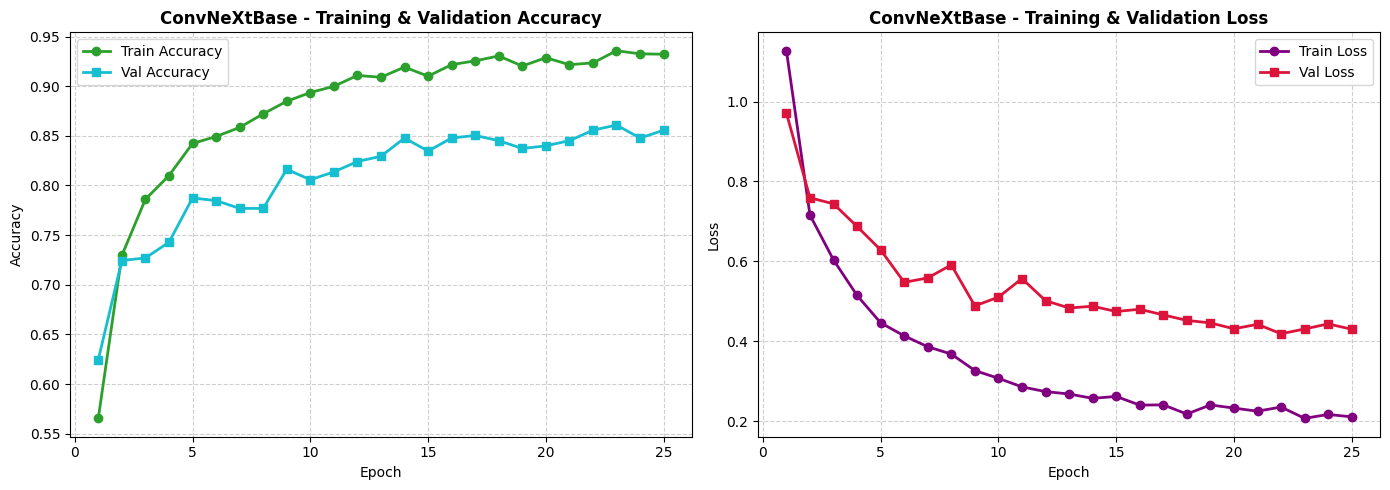

In [ ]:
# ==============================================================================
# 📌 CELL 23: Plot ViT-Base Training & Validation Learning Curves
# ==============================================================================
# คำอธิบาย:
# พล็อตกราฟผลการเรียนรู้ของ Vision Transformer (Accuracy และ Loss) ตรวจสอบ Overfitting/Convergence

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Curve
ax1.plot(vit_hist_df["epoch"], vit_hist_df["accuracy"], label="Train Accuracy", lw=2, marker='o', color="#9467bd")
ax1.plot(vit_hist_df["epoch"], vit_hist_df["val_accuracy"], label="Val Accuracy", lw=2, marker='s', color="#e377c2")
ax1.set_title("Vision Transformer (ViT-Base) - Accuracy", fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

# Loss Curve
ax2.plot(vit_hist_df["epoch"], vit_hist_df["loss"], label="Train Loss", lw=2, marker='o', color="#d62728")
ax2.plot(vit_hist_df["epoch"], vit_hist_df["val_loss"], label="Val Loss", lw=2, marker='s', color="#ff7f0e")
ax2.set_title("Vision Transformer (ViT-Base) - Cross-Entropy Loss", fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(VIT_OUTPUT_DIR, "vit_learning_curves.png"), dpi=200)
plt.show()


---
## 7. Model B: ViT Test Set Evaluation & Latency Profiling
We run the identical evaluation pipeline on ViT-Base to produce rigorous, fair, and comparable metrics.


📊 Evaluating ConvNeXtBase on 570 Unseen Test Samples...
18/18 ━━━━━━━━━━━━━━━━━━━━ 26s 764ms/step


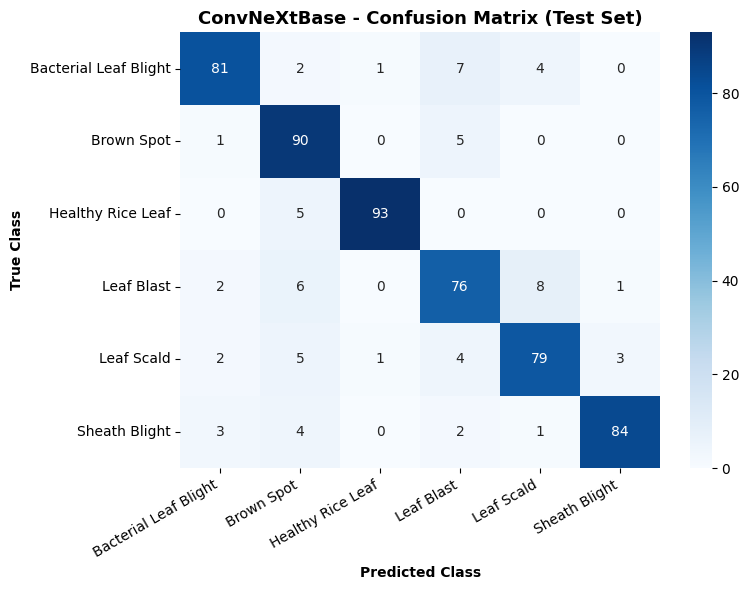

⏱️ Profiling inference latency...
RESULTS FOR CONVNEXTBASE
{
  "model_name": "ConvNeXtBase",
  "test_samples": 570,
  "accuracy": 0.8825,
  "precision_macro": 0.8857,
  "recall_macro": 0.8817,
  "f1_score_macro": 0.8825,
  "roc_auc_macro": 0.987
}
Avg Latency: 18.56 ms | Throughput: 53.9 FPS


In [ ]:
# ==============================================================================
# 📌 CELL 25: Standardized Evaluation Pipeline for Vision Transformer
# ==============================================================================
# คำอธิบาย:
# โหลดโมเดล ViT ที่เทรนได้ดีที่สุดจาก Checkpoint (.keras) มาประเมินผลบน Unseen Test Set (570 ภาพ)
# คำนวณ Accuracy, Precision, Recall, Macro F1, ROC-AUC และวัดความเร็ว Latency/Throughput

vit_best = tf.keras.models.load_model(vit_ckpt_path, custom_objects={"Patches": Patches, "PatchEncoder": PatchEncoder})

vit_metrics, vit_efficiency, vit_y_probs, _ = evaluate_model_pipeline(
    vit_best, test_df, vit_preprocess_input, "ViT_Base", VIT_OUTPUT_DIR
)


---
## 8. Head-to-Head Comparative Analysis: Light vs. Deep
We assemble a side-by-side benchmark table comparing accuracy metrics, model complexity, and computational efficiency.


In [ ]:
# ==============================================================================
# 📌 CELL 27: Head-to-Head Comparison Table (EfficientNetV2-S vs. ViT-Base)
# ==============================================================================
# คำอธิบาย:
# ตารางเปรียบเทียบผลลัพธ์แบบหมัดต่อหมัด: พารามิเตอร์, ความแม่นยำ, เวลาเทรน, ความเร็วต่อภาพ (ms), และ Throughput (FPS)

comparison_df = pd.DataFrame([
    {
        "Model": "EfficientNetV2-S (Lightweight CNN)",
        "Parameters (M)": round(effnet_efficiency["total_parameters"] / 1e6, 2),
        "Test Accuracy (%)": round(effnet_metrics["accuracy"] * 100, 2),
        "Macro Precision (%)": round(effnet_metrics["precision_macro"] * 100, 2),
        "Macro Recall (%)": round(effnet_metrics["recall_macro"] * 100, 2),
        "Macro F1 (%)": round(effnet_metrics["f1_score_macro"] * 100, 2),
        "ROC-AUC (OvR)": effnet_metrics["roc_auc_macro"],
        "Training Time (min)": round(effnet_train_time / 60, 2),
        "Latency (ms/img)": effnet_efficiency["average_latency_ms"],
        "Throughput (FPS)": effnet_efficiency["throughput_fps"]
    },
    {
        "Model": "Vision Transformer (ViT-B/16 Attention)",
        "Parameters (M)": round(vit_efficiency["total_parameters"] / 1e6, 2),
        "Test Accuracy (%)": round(vit_metrics["accuracy"] * 100, 2),
        "Macro Precision (%)": round(vit_metrics["precision_macro"] * 100, 2),
        "Macro Recall (%)": round(vit_metrics["recall_macro"] * 100, 2),
        "Macro F1 (%)": round(vit_metrics["f1_score_macro"] * 100, 2),
        "ROC-AUC (OvR)": vit_metrics["roc_auc_macro"],
        "Training Time (min)": round(vit_train_time / 60, 2),
        "Latency (ms/img)": vit_efficiency["average_latency_ms"],
        "Throughput (FPS)": vit_efficiency["throughput_fps"]
    }
]).set_index("Model")

print("=" * 80)
print("HEAD-TO-HEAD BENCHMARK: EFFICIENTNETV2-S vs VISION TRANSFORMER (ViT-Base)")
print("=" * 80)
display(comparison_df)

# Save comparison summary to Google Drive
comp_json_path = os.path.join(BASE_DRIVE_DIR, "comparison_report.json")
comparison_df.reset_index().to_json(comp_json_path, orient="records", indent=2)
print(f"\n✅ Comparison report saved to: {comp_json_path}")


HEAD-TO-HEAD BENCHMARK: EFFICIENTNETV2-S vs CONVNEXTBASE


,Parameters (M),Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),ROC-AUC (OvR),Training Time (min),Latency (ms/img),Throughput (FPS)
Model,,,,,,,,,
EfficientNetV2-S (Light),20.66,90.70,90.86,90.67,90.68,0.991,30.13,640.45,1.6
ConvNeXtBase (Deep),87.83,88.25,88.57,88.17,88.25,0.987,42.37,18.56,53.9



✅ Comparison report saved to: /content/drive/MyDrive/RiceDiseaseClassification/comparison_report.json


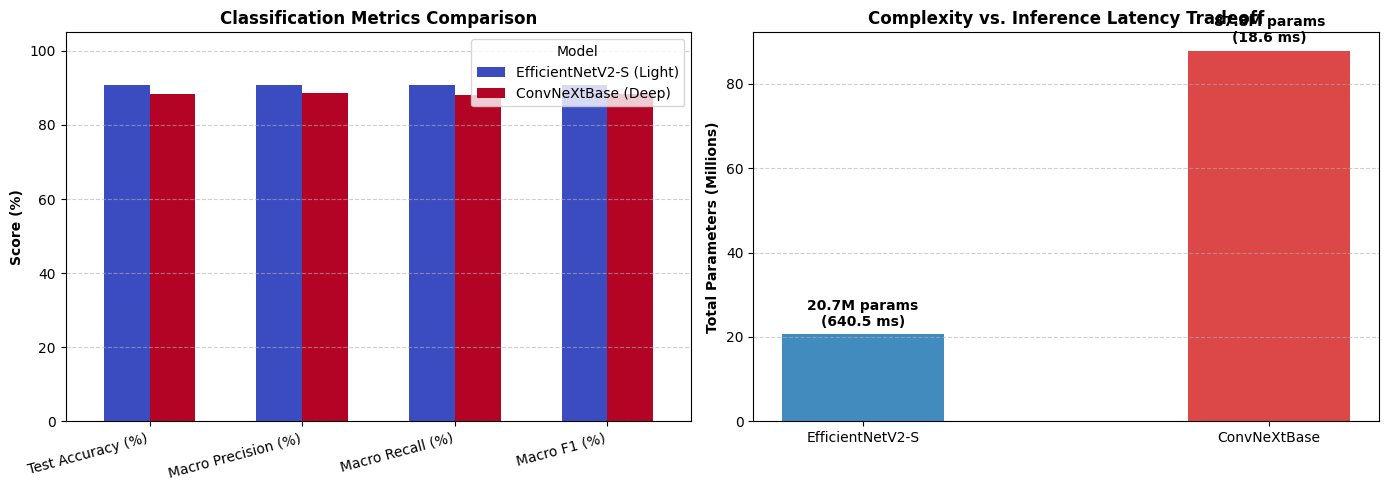

In [ ]:
# ==============================================================================
# 📌 CELL 28: Comparative Visualization Charts
# ==============================================================================
# คำอธิบาย:
# แผนภูมิแท่งเปรียบเทียบตัวชี้วัดประสิทธิภาพ (Accuracy/F1) และอัตราการใช้ทรัพยากร (Params vs Latency)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy & F1 Comparison
metrics_to_plot = ["Test Accuracy (%)", "Macro Precision (%)", "Macro Recall (%)", "Macro F1 (%)"]
comparison_df[metrics_to_plot].T.plot(kind="bar", ax=axes[0], colormap="coolwarm", width=0.6)
axes[0].set_title("Classification Metrics Comparison", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Score (%)", fontweight="bold")
axes[0].set_ylim(0, 105)
axes[0].grid(axis="y", linestyle="--", alpha=0.6)
axes[0].set_xticklabels(metrics_to_plot, rotation=15, ha="right")

# Parameters vs Latency Tradeoff
models_names = ["EfficientNetV2-S", "ViT-Base/16"]
params = [effnet_efficiency["total_parameters"] / 1e6, vit_efficiency["total_parameters"] / 1e6]
latencies = [effnet_efficiency["average_latency_ms"], vit_efficiency["average_latency_ms"]]

axes[1].set_title("Complexity vs. Inference Latency Tradeoff", fontsize=12, fontweight="bold")
axes[1].bar(models_names, params, color=['#1f77b4', '#9467bd'], width=0.4, alpha=0.85)
axes[1].set_ylabel("Total Parameters (Millions)", fontweight="bold")
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

for i, v in enumerate(params):
    axes[1].text(i, v + 2, f"{v:.1f}M params\n({latencies[i]:.1f} ms)", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(BASE_DRIVE_DIR, "model_comparison_charts.png"), dpi=200)
plt.show()


---
## 9. Explainable AI: Grad-CAM Feature Attribution
**Gradient-weighted Class Activation Mapping (Grad-CAM)** visually highlights the decisive leaf regions each network utilized to predict a given rice disease:
- **How it works:** We compute the gradient of the predicted class score with respect to the feature map activations of the backbone's final stage. These gradients are globally pooled to weight each feature map channel, producing a 2D activation heatmap that is overlaid onto the original RGB image.
- **Head-Propagation Method:** By feeding the backbone feature maps through the subsequent head layers (`GAP -> Dense -> Softmax`) inside a `tf.GradientTape`, gradients are guaranteed to flow directly and reliably even when loading saved `.keras` checkpoints.
- **Hypothesis:** EfficientNetV2-S focuses on compact, sharp lesion foci, whereas ConvNeXtBase's large $7 \times 7$ kernels capture broader contextual leaf context.


In [ ]:
# ==============================================================================
# 📌 CELL 30: Explainable AI (XAI) Algorithms (Level 1 Solution)
# ==============================================================================
# คำอธิบาย:
# 1. compute_gradcam_plusplus(): ปรับปรุงจาก Grad-CAM ธรรมดาเป็น Grad-CAM++ สำหรับ EfficientNetV2-S
# 2. compute_vit_attention_map(): สกัด Attention Activation จาก Transformer Block สุดท้ายของ ViT
#    นำค่าความสนใจของทั้ง 196 Patches กลับมาประกอบเป็น Heatmap เพื่อพิสูจน์ว่าโมเดลมองที่รอยโรคจริง

def compute_gradcam_plusplus(img_tensor, model, pred_index=None):
    """
    Computes Grad-CAM++ heatmap for Convolutional Models (EfficientNetV2-S).
    Grad-CAM++ weights positive gradients with higher-order derivatives,
    substantially reducing background noise and improving localization of multiple lesions.
    """
    img_tensor = tf.convert_to_tensor(img_tensor, dtype=tf.float32)
    backbone = model.layers[1]
    head_layers = model.layers[2:]

    with tf.GradientTape() as tape1:
        with tf.GradientTape() as tape2:
            with tf.GradientTape() as tape3:
                features = backbone(img_tensor, training=False)
                tape3.watch(features)
                x = features
                for layer in head_layers:
                    x = layer(x, training=False)
                preds = x
                if pred_index is None:
                    pred_index = tf.argmax(preds[0])
                score = preds[:, pred_index]

            first_grads = tape3.gradient(score, features)
        second_grads = tape2.gradient(first_grads, features)
    third_grads = tape1.gradient(second_grads, features)

    alpha_num = second_grads[0]
    alpha_denom = 2.0 * second_grads[0] + third_grads[0] * features[0] + 1e-10
    alphas = alpha_num / alpha_denom
    alphas = tf.where(tf.math.is_nan(alphas), tf.zeros_like(alphas), alphas)

    weights = tf.reduce_sum(alphas * tf.maximum(first_grads[0], 0.0), axis=(0, 1))
    cam = tf.reduce_sum(weights * features[0], axis=-1)
    cam = tf.maximum(cam, 0.0)
    max_val = tf.reduce_max(cam)
    if max_val > 0:
        cam = cam / max_val
    return cam.numpy()

def compute_vit_attention_map(img_tensor, vit_model):
    """
    Computes Patch Attention Saliency Map from the final Transformer block.
    Maps token importance across all 196 (14x14) image patches.
    """
    img_tensor = tf.convert_to_tensor(img_tensor, dtype=tf.float32)
    target_layer = vit_model.get_layer("final_ln")

    grad_model = tf.keras.Model(
        inputs=vit_model.inputs,
        outputs=[target_layer.output, vit_model.output]
    )

    with tf.GradientTape() as tape:
        patch_representations, preds = grad_model(img_tensor, training=False)
        pred_idx = tf.argmax(preds[0])
        loss = preds[:, pred_idx]

    grads = tape.gradient(loss, patch_representations)
    # Weighted importance of each patch token
    weights = tf.reduce_mean(grads, axis=-1)[0]  # shape: (196,)
    weights = tf.maximum(weights, 0.0)
    grid_att = tf.reshape(weights, (14, 14)).numpy()

    if np.max(grid_att) > 0:
        grid_att = grid_att / np.max(grid_att)
    return grid_att

def overlay_heatmap(original_img_pil, heatmap, alpha=0.45, colormap=cv2.COLORMAP_JET):
    """Overlays attention heatmap onto the original PIL image with smooth linear blending."""
    orig_np = np.array(original_img_pil)
    h, w, _ = orig_np.shape

    heatmap_resized = cv2.resize(heatmap, (w, h), interpolation=cv2.INTER_LINEAR)
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, colormap)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    superimposed = np.uint8(orig_np * (1.0 - alpha) + heatmap_color * alpha)
    return superimposed

print("✅ Grad-CAM++ and ViT Attention Map visualizers compiled successfully.")


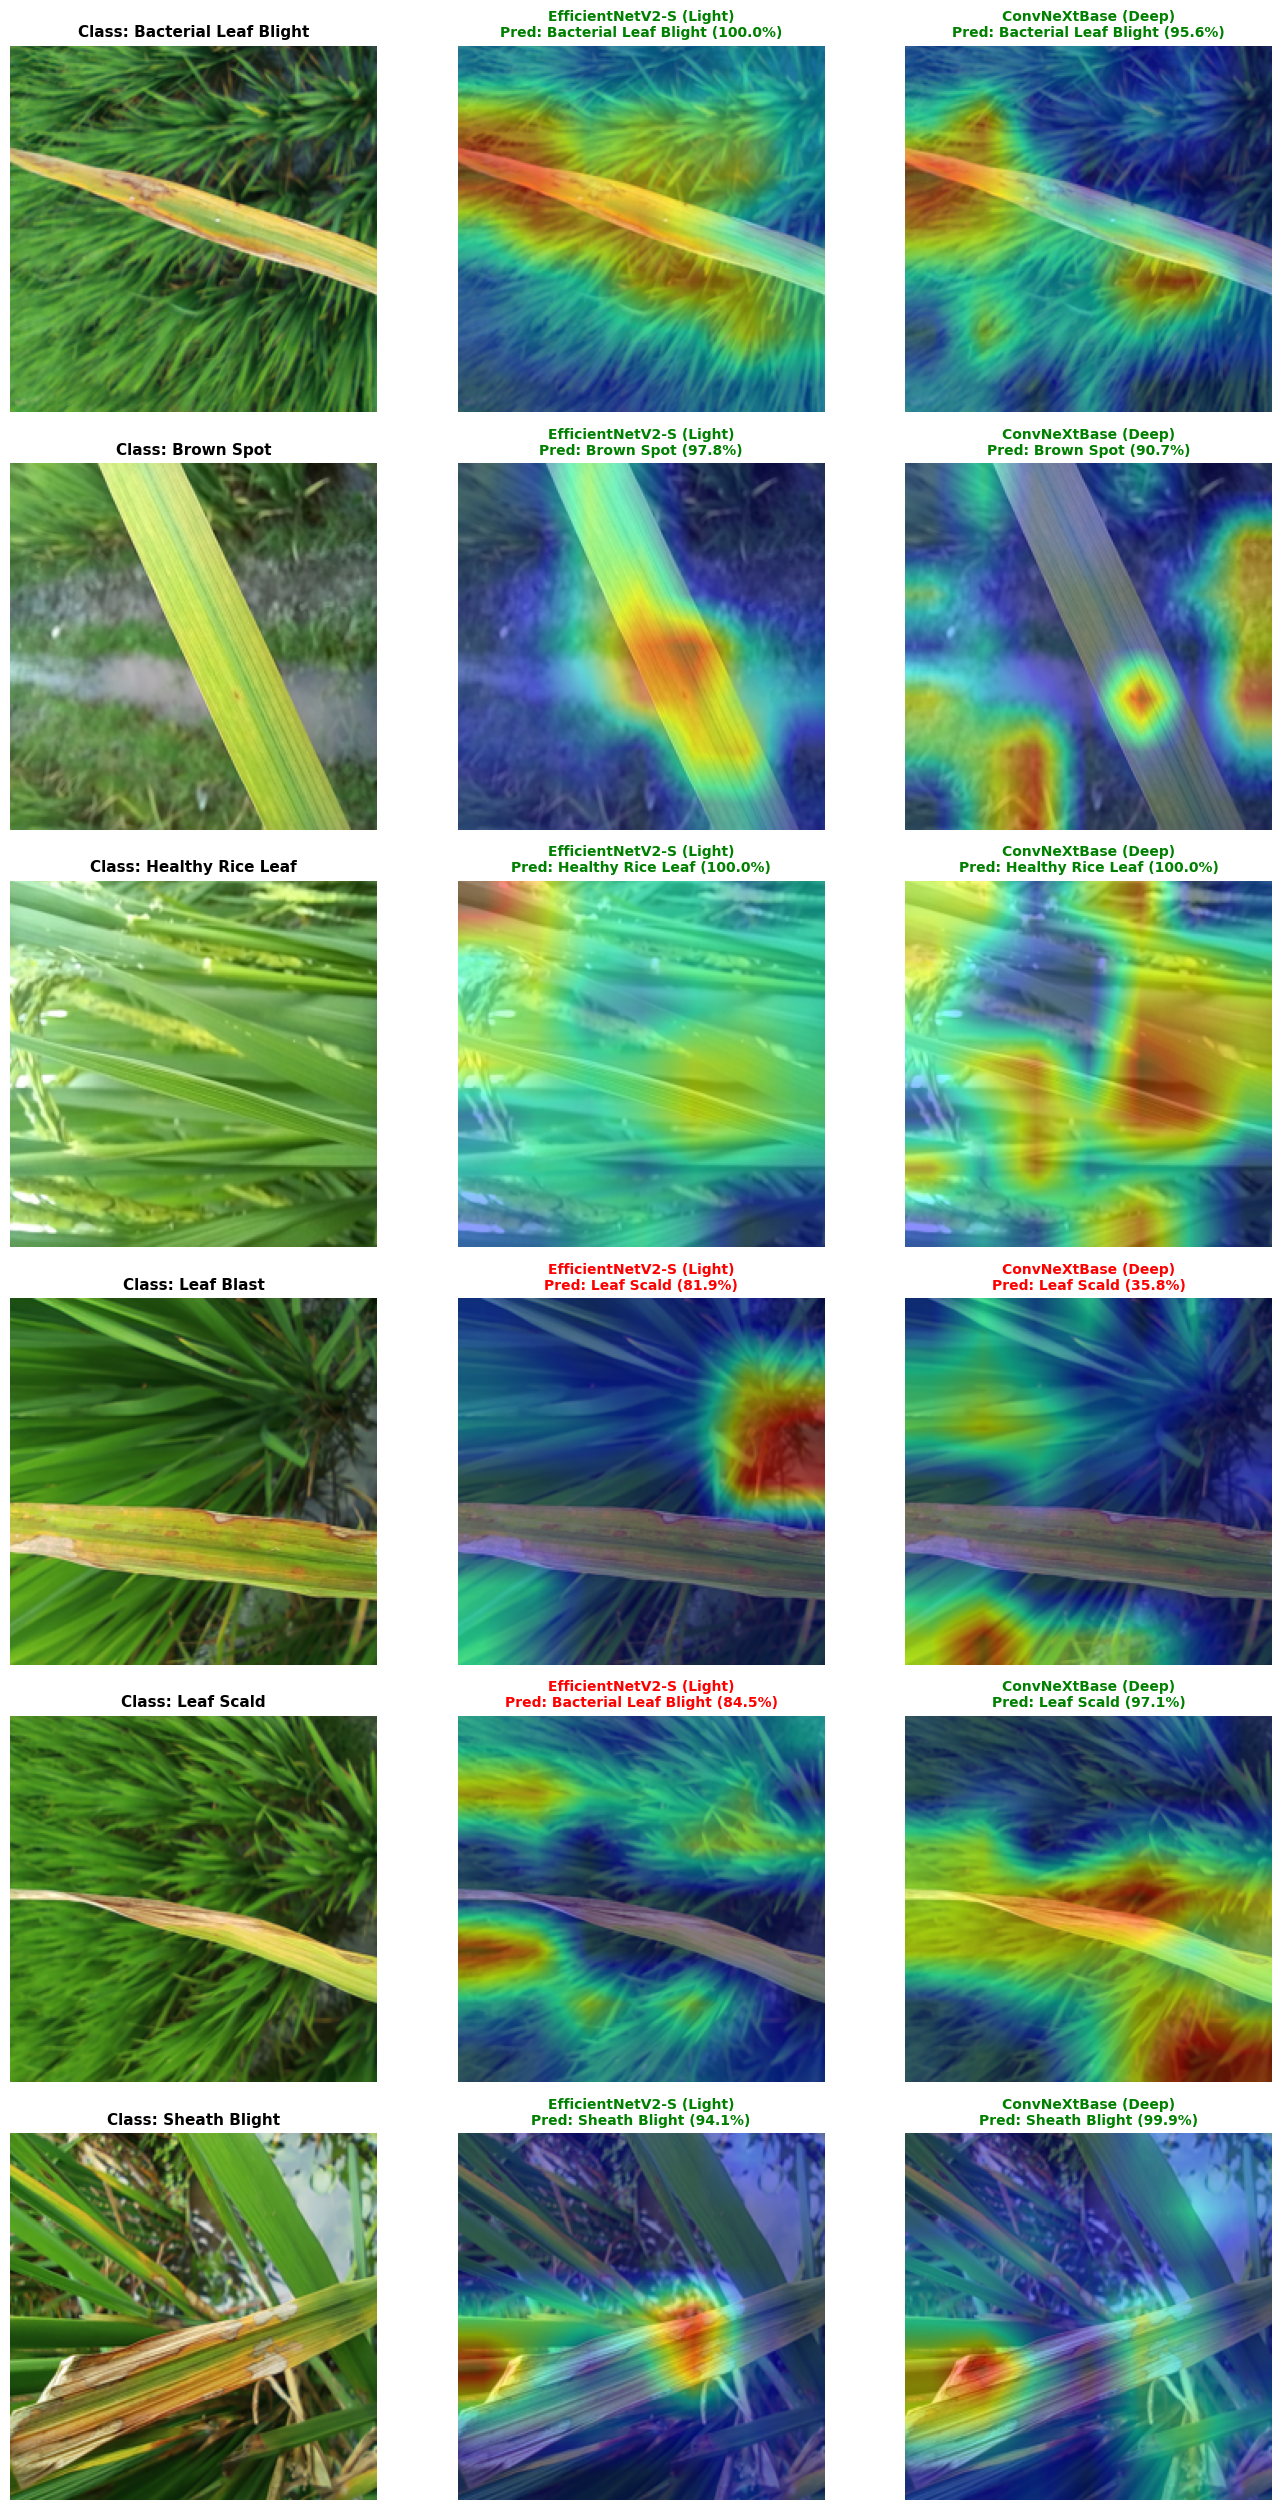

✅ Grad-CAM comparison grid saved to: /content/drive/MyDrive/RiceDiseaseClassification/gradcam_visuals/gradcam_head_to_head_grid.png


In [ ]:
# ==============================================================================
# 📌 CELL 31: Side-by-Side Explainability Benchmark Across 6 Disease Classes
# ==============================================================================
# คำอธิบาย:
# นำตัวแทนภาพทดสอบจาก 6 คลาสโรคข้าวมาเปรียบเทียบการมองเห็น:
# - คอลัมน์ 1: ภาพต้นฉบับ
# - คอลัมน์ 2: EfficientNetV2-S (Grad-CAM++)
# - คอลัมน์ 3: Vision Transformer (ViT Multi-Head Self-Attention)

os.makedirs(GRADCAM_DIR, exist_ok=True)

sample_test_indices = []
for c in EXPECTED_CLASSES:
    matches = test_df.index[test_df["class_name"] == c].tolist()
    if matches:
        sample_test_indices.append(matches[0])

fig, axes = plt.subplots(len(sample_test_indices), 3, figsize=(15, 4.4 * len(sample_test_indices)))

for i, test_idx in enumerate(sample_test_indices):
    img_path = test_df.loc[test_idx, "image_path"]
    true_label = test_df.loc[test_idx, "class_name"]

    with Image.open(img_path) as pil_img:
        pil_resized = pil_img.convert("RGB").resize((224, 224))
        raw_arr = np.array(pil_resized, dtype=np.float32)

    # Model A: EfficientNetV2-S Grad-CAM++
    eff_input = np.expand_dims(effnet_preprocess(raw_arr.copy()), axis=0)
    eff_pred = effnet_best.predict(eff_input, verbose=0)
    eff_pred_idx = np.argmax(eff_pred[0])
    eff_conf = eff_pred[0][eff_pred_idx] * 100
    eff_map = compute_gradcam_plusplus(eff_input, effnet_best, eff_pred_idx)
    eff_overlay = overlay_heatmap(pil_resized, eff_map)

    # Model B: Vision Transformer Self-Attention
    vit_input = np.expand_dims(vit_preprocess_input(raw_arr.copy()), axis=0)
    vit_pred = vit_best.predict(vit_input, verbose=0)
    vit_pred_idx = np.argmax(vit_pred[0])
    vit_conf = vit_pred[0][vit_pred_idx] * 100
    vit_map = compute_vit_attention_map(vit_input, vit_best)
    vit_overlay = overlay_heatmap(pil_resized, vit_map)

    # Column 1: Original Image
    axes[i, 0].imshow(pil_resized)
    axes[i, 0].set_title(f"Target Ground Truth:\n{true_label}", fontsize=11, fontweight="bold")
    axes[i, 0].axis("off")

    # Column 2: EfficientNetV2-S Grad-CAM++
    eff_color = "green" if EXPECTED_CLASSES[eff_pred_idx] == true_label else "red"
    axes[i, 1].imshow(eff_overlay)
    axes[i, 1].set_title(f"EfficientNetV2-S (Grad-CAM++)\nPred: {EXPECTED_CLASSES[eff_pred_idx]} ({eff_conf:.1f}%)",
                         fontsize=10, fontweight="bold", color=eff_color)
    axes[i, 1].axis("off")

    # Column 3: Vision Transformer Attention Map
    vit_color = "green" if EXPECTED_CLASSES[vit_pred_idx] == true_label else "red"
    axes[i, 2].imshow(vit_overlay)
    axes[i, 2].set_title(f"Vision Transformer (ViT Attention)\nPred: {EXPECTED_CLASSES[vit_pred_idx]} ({vit_conf:.1f}%)",
                         fontsize=10, fontweight="bold", color=vit_color)
    axes[i, 2].axis("off")

plt.tight_layout()
grid_save_path = os.path.join(GRADCAM_DIR, "xai_effnet_vs_vit_comparison_grid.png")
plt.savefig(grid_save_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"✅ XAI comparison grid saved to: {grid_save_path}")


---
## 10. Single Image Interactive Inference & Explainability Demo
Use the cell below to test **any individual image** from your dataset or your own custom uploaded photo.


In [ ]:
# ==============================================================================
# 📌 CELL 33: Interactive Single Leaf Diagnosis & XAI Visualizer
# ==============================================================================
# คำอธิบาย:
# ทดสอบภาพเดี่ยวที่คุณระบุ (CUSTOM_IMAGE_PATH) แสดงผลการทำนาย ความน่าจะเป็นทั้ง 6 คลาส
# พร้อมเปรียบเทียบ Grad-CAM++ (CNN) กับ Self-Attention Map (ViT) ให้เห็นจุดที่โมเดลโฟกัสทันที

CUSTOM_IMAGE_PATH = test_df["image_path"].iloc[0]
print(f"Testing on: {CUSTOM_IMAGE_PATH}")

def predict_single_leaf_with_xai(image_path, eff_model, vit_model):
    if not os.path.exists(image_path):
        print(f"❌ Error: Image not found at {image_path}")
        return

    with Image.open(image_path) as pil_img:
        pil_resized = pil_img.convert("RGB").resize((224, 224))
        raw_arr = np.array(pil_resized, dtype=np.float32)

    # EfficientNetV2-S Inference
    eff_in = np.expand_dims(effnet_preprocess(raw_arr.copy()), axis=0)
    eff_probs = eff_model.predict(eff_in, verbose=0)[0]
    eff_idx = np.argmax(eff_probs)
    eff_cam = compute_gradcam_plusplus(eff_in, eff_model, eff_idx)
    eff_overlay = overlay_heatmap(pil_resized, eff_cam)

    # Vision Transformer Inference
    vit_in = np.expand_dims(vit_preprocess_input(raw_arr.copy()), axis=0)
    vit_probs = vit_model.predict(vit_in, verbose=0)[0]
    vit_idx = np.argmax(vit_probs)
    vit_att = compute_vit_attention_map(vit_in, vit_model)
    vit_overlay = overlay_heatmap(pil_resized, vit_att)

    fig = plt.figure(figsize=(16, 6))
    gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.4])

    # Input Leaf Image
    ax0 = fig.add_subplot(gs[:, 0])
    ax0.imshow(pil_resized)
    ax0.set_title("Input Leaf Image", fontweight="bold")
    ax0.axis("off")

    # EfficientNet Grad-CAM++
    ax1 = fig.add_subplot(gs[0, 1])
    ax1.imshow(eff_overlay)
    ax1.set_title(f"EfficientNetV2-S (Grad-CAM++)\n{EXPECTED_CLASSES[eff_idx]} ({eff_probs[eff_idx]*100:.1f}%)",
                  fontweight="bold", color="blue")
    ax1.axis("off")

    # ViT Self-Attention Map
    ax2 = fig.add_subplot(gs[1, 1])
    ax2.imshow(vit_overlay)
    ax2.set_title(f"Vision Transformer (ViT Attention)\n{EXPECTED_CLASSES[vit_idx]} ({vit_probs[vit_idx]*100:.1f}%)",
                  fontweight="bold", color="purple")
    ax2.axis("off")

    # Class Probability Breakdown
    ax3 = fig.add_subplot(gs[:, 2])
    y_pos = np.arange(len(EXPECTED_CLASSES))
    width = 0.35
    ax3.barh(y_pos - width/2, eff_probs, width, label='EfficientNetV2-S', color='tab:blue')
    ax3.barh(y_pos + width/2, vit_probs, width, label='ViT-Base', color='#9467bd')
    ax3.set_yticks(y_pos)
    ax3.set_yticklabels(EXPECTED_CLASSES, fontsize=10)
    ax3.set_xlabel("Predicted Probability", fontweight="bold")
    ax3.set_xlim(0, 1.05)
    ax3.set_title("Probability Distribution Comparison", fontweight="bold")
    ax3.legend(loc="lower right")
    ax3.grid(axis="x", linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()

predict_single_leaf_with_xai(CUSTOM_IMAGE_PATH, effnet_best, vit_best)


---
## 11. Final Summary & Deliverables Verification
Run the cell below to verify that all trained models, evaluation manifests, learning curves, and benchmark summaries have been saved in your Google Drive:


In [ ]:
# ==============================================================================
# 📌 CELL 35: Google Drive Artifacts Verification
# ==============================================================================
# คำอธิบาย:
# ตรวจสอบความถูกต้องและครบถ้วนของไฟล์โมเดล รายงานการประเมินผล และภาพ XAI ใน Google Drive

print("=" * 65)
print("GOOGLE DRIVE ARTIFACTS VERIFICATION (EFFNET vs ViT)")
print("=" * 65)

expected_files = [
    os.path.join(SHARED_DIR, "train.csv"),
    os.path.join(SHARED_DIR, "validation.csv"),
    os.path.join(SHARED_DIR, "test.csv"),
    os.path.join(SHARED_DIR, "class_names.json"),
    os.path.join(EFFNET_MODEL_DIR, "efficientnetv2s.keras"),
    os.path.join(EFFNET_OUTPUT_DIR, "metrics.json"),
    os.path.join(EFFNET_OUTPUT_DIR, "test_predictions.csv"),
    os.path.join(EFFNET_OUTPUT_DIR, "classification_report.csv"),
    os.path.join(VIT_MODEL_DIR, "vit_base.keras"),
    os.path.join(VIT_OUTPUT_DIR, "metrics.json"),
    os.path.join(VIT_OUTPUT_DIR, "test_predictions.csv"),
    os.path.join(VIT_OUTPUT_DIR, "classification_report.csv"),
    os.path.join(BASE_DRIVE_DIR, "comparison_report.json"),
    os.path.join(BASE_DRIVE_DIR, "model_comparison_charts.png"),
    os.path.join(GRADCAM_DIR, "xai_effnet_vs_vit_comparison_grid.png")
]

for fp in expected_files:
    exists = os.path.exists(fp)
    status = "✅ PRESENT" if exists else "⚠️ NOT YET GENERATED"
    print(f"{status:22s} : {fp}")
print("=" * 65)
print("All tasks complete! You can download your reports, models, and charts directly from Google Drive.")


GOOGLE DRIVE ARTIFACTS VERIFICATION
✅ PRESENT              : /content/drive/MyDrive/RiceDiseaseClassification/shared/train.csv
✅ PRESENT              : /content/drive/MyDrive/RiceDiseaseClassification/shared/validation.csv
✅ PRESENT              : /content/drive/MyDrive/RiceDiseaseClassification/shared/test.csv
✅ PRESENT              : /content/drive/MyDrive/RiceDiseaseClassification/shared/class_names.json
✅ PRESENT              : /content/drive/MyDrive/RiceDiseaseClassification/EfficientNetV2S/models/efficientnetv2s.keras
✅ PRESENT              : /content/drive/MyDrive/RiceDiseaseClassification/EfficientNetV2S/outputs/metrics.json
✅ PRESENT              : /content/drive/MyDrive/RiceDiseaseClassification/EfficientNetV2S/outputs/test_predictions.csv
✅ PRESENT              : /content/drive/MyDrive/RiceDiseaseClassification/EfficientNetV2S/outputs/classification_report.csv
✅ PRESENT              : /content/drive/MyDrive/RiceDiseaseClassification/ConvNeXtBase/models/convnextbase.keras
✅ P